# Health — analysis (ADM2 panel)

Effect of upstream land-cover change on health in downstream municipalities. The
specification implements the decision table in §9 of
[`01_descriptives.ipynb`](01_descriptives.ipynb); the sample, outcome and exposure
construction lives in `src/analysis/health.py`.

**Baseline specification** (one regression per outcome, `pyfixest.fepois`):

```
count ~ alr_pasture + alr_agriculture + alr_farming_unclassified + alr_urban + alr_other        (upstream, ≤ 200 km)
      + local_alr_pasture + … + local_alr_other                                               (local)
      + local_2t + local_tp + local_swvl1
      + offset(log exposure)
  | municipality + state×year
```

| Element | Choice |
|---|---|
| Sample | municipality-years 2000–2024 with population and local climate (5,562 municipalities); headwater municipalities stay in with upstream ALR set to 0, absorbed by the municipality FE |
| Estimator | PPML on counts; exposure offset: population (hospitalizations), live births (infant and under-5 deaths), births with known weight / gestation (low birth weight / preterm) |
| Outcomes | primary: ICD 01 infectious/parasitic, ICD 11 digestive, gastrointestinal channel, infant deaths, low birth weight. Secondary: ICD 14, 16, 17; renal, skin, leptospirosis, toxic-poisoning, vector-borne channels; under-5 deaths; preterm (2012–2024). Placebo: ICD 19 injury/poisoning, injuries and mental-health channels |
| Exposure | upstream land cover in 25 km rings up to **200 km**, inv-sqrt kernel, next to the municipality's own (local) rings; ALR against natural land |
| Controls | local annual temperature, precipitation and top-layer soil moisture |
| Mining | not in the baseline; separate mining arm in §9 (mining within 50 km upstream next to local mining, on municipalities with upstream mining) |
| Inference | cluster by Otto level-3 basin (`otto_basin_l3`); §8 compares state and Otto 4 and adds wild-cluster score-bootstrap p-values |

**Reading the coefficients.** ALR regressors are logs of the class-to-natural-land ratio
and PPML coefficients are on the log scale of the rate, so β is an elasticity: a 10%
higher pasture-to-natural ratio changes the rate by about β·10 %. §1 converts them to
effects of one within-municipality SD of exposure.

## Summary (run of 2026-10-22)

**Upstream land-cover change has no detectable effect on health in downstream
municipalities, with one suggestive exception: mining onset upstream in the Amazon.** Identification rests on 0.4–2% of the exposure variation (descriptives
§4), but the PPML estimates are precise enough to rule out more than small effects.

- **Pasture and agriculture.** No upstream pasture or agriculture coefficient is
  significant for any primary outcome (infectious/parasitic, digestive, gastrointestinal
  hospitalizations, infant deaths, low birth weight). Per within-municipality SD of
  exposure, the 95% CIs exclude increases above about 0.6% (pasture) and 1.1%
  (agriculture) in every primary outcome. Most point estimates for water-related
  outcomes are negative.
- **No outcome responds more than the placebo.** No upstream coefficient differs from the
  injury placebo at 5% (stacked PPML, bootstrap). Where the differences come close
  (pasture and agriculture → infectious, p ≈ 0.05), the water outcome responds *less*
  than injuries.
- **Other classes.** 4 of 40 upstream coefficients pass the score bootstrap at 5%
  (2 expected by chance). Unclassified farming → low birth weight −0.7% and digestive
  +1.0% per SD, "other" land → infant deaths +0.7% per SD, and "other" → the
  mental-health placebo. None is part of a consistent pattern.
- **The local block absorbs confounding, as intended.** Local urbanization has the largest
  coefficients, and they are largest for the injury placebos (+0.23, +0.26). That points
  to local development and access to hospital care, not water. The one water-plausible
  local association is local pasture → gastrointestinal hospitalizations (+0.16,
  bootstrap p = 0.02), which exceeds the placebo only marginally (p = 0.06).
- **Robustness.** OLS on log rates, dropping 2020–21, the upstream climate block, the
  utilization control, 2008–2024 and municipalities with upstream rings only give the
  same picture. Municipality + biome×year FE make the injury placebo positive and
  significant (+0.09), which supports state×year FE. Distance bands and biome slopes show
  no water pattern. The clearest heterogeneity is in the placebo: frontier pasture
  (Amazon +0.25, Cerrado +0.20) goes with more injury hospitalizations.
- **Mining (§9).** Pooled over the 1,190 municipalities with mining within 50 km upstream,
  mining has no robust effect on metal-related outcomes: 2 of 44 mining coefficients pass
  the bootstrap, about chance, and both are local. **In the Amazon**, where mercury-using
  gold mining is concentrated, mining appearing upstream raises infant deaths by about
  23% (+0.21, bootstrap p = 0.002). The same slope is −0.02 elsewhere, and the injury
  placebo does not move. The event study shows the rise from the year after onset, and
  it persists. This result is suggestive, not conclusive: it rests on 36 onsets in 18
  basins, there is a small pre-onset bump at year −2, and it survives a Bonferroni
  correction across the 22 regional tests only narrowly.

Read together with the pollution arm (pasture → lead and cadmium violations, agriculture
→ COD, mining → mercury violations), the broad land-cover changes that move river water
quality do not translate into measurable health effects at municipality level. Mining is
the exception, and only where it brings mercury: the Amazon infant-mortality effect is
consistent with the pollution arm's mercury result.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyfixest as pf

from src.analysis.core import descriptives as desc
from src.analysis.health import model as H
from src.analysis.core import panels
from src.analysis.core.inference import poisson_score_bootstrap

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# pyfixest drops singleton FE groups and separated observations by design;
# its per-model warnings would otherwise flood the output.
warnings.filterwarnings("ignore", message=r".*singleton fixed effect")
warnings.filterwarnings("ignore", message=r".*removed because of separation")

RESULTS_DIR = PROJECT_ROOT / "output" / "analysis" / "health"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Estimation panel

In [2]:
df = H.build_health_panel(distance_bands=True)
municipalities = df.drop_duplicates("mun_id")
print(f"{len(df):,} municipality-years · {len(municipalities):,} municipalities "
      f"({(~municipalities['has_upstream']).sum()} headwater) · {df.year.min()}–{df.year.max()} · "
      f"{df['otto_basin_l3'].nunique()} Otto-3 basins")

ROLES = {**{n: "primary" for n in H.PRIMARY_OUTCOMES}, **{n: "secondary" for n in H.SECONDARY_OUTCOMES},
         **{n: "placebo" for n in H.PLACEBO_OUTCOMES}, **{n: "mining arm" for n in H.METAL_OUTCOMES}}
outcome_rows = {}
for name, (count, exposure) in H.OUTCOMES.items():
    observed = df[df[H.outcome_column(name)].notna() & df[H.offset_column(name)].notna()]
    y = observed[H.outcome_column(name)]
    outcome_rows[name] = {"role": ROLES[name], "count": count, "exposure": exposure, "n": len(observed),
                          "events per year": y.sum() / observed["year"].nunique(),
                          "rate per 1,000 exposure": 1000 * y.sum() / observed[exposure].sum(),
                          "share zero": (y == 0).mean()}
display(pd.DataFrame(outcome_rows).T)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

138,912 municipality-years · 5,562 municipalities (215 headwater) · 2000–2024 · 217 Otto-3 basins


,role,count,exposure,n,events per year,"rate per 1,000 exposure",share zero
infectious_parasitic,primary,hosp_icd_01,population,138912,9.469e+05,4.805,0.003347
digestive,primary,hosp_icd_11,population,138912,1.068e+06,5.419,0.001289
gastrointestinal,primary,hosp_water_sanitation_gastrointestinal,population,138912,3.721e+05,1.888,0.07209
infant_deaths,primary,deaths_under_1,births,138867,4.257e+04,14.75,0.2251
low_birth_weight,primary,births_low_weight,births_weight_known,138885,2.438e+05,84.73,0.02403
genitourinary,secondary,hosp_icd_14,population,138912,7.964e+05,4.042,0.002361
perinatal,secondary,hosp_icd_16,population,138912,2.517e+05,1.277,0.05799
congenital,secondary,hosp_icd_17,population,138912,8.281e+04,0.4202,0.1407
renal_urinary,secondary,hosp_renal_urinary_toxic_water,population,138912,4.837e+05,2.455,0.008466
skin_contact,secondary,hosp_skin_contact,population,138912,2.095e+05,1.063,0.07356


**Magnitudes.** Within-municipality SD of each exposure term after municipality +
state×year FE (upstream terms over municipalities with upstream rings), and the implied
effect of one SD for a coefficient of 0.1.

In [3]:
UPSTREAM, LOCAL = H.UPSTREAM_REGRESSORS, H.LOCAL_REGRESSORS
within_sd = pd.concat([
    desc.demean(df[df["has_upstream"]], UPSTREAM, ["mun_id", "state_year"]).std(),
    desc.demean(df, LOCAL, ["mun_id", "state_year"]).std(),
])
display(pd.DataFrame({"within SD": within_sd, "effect of 1 SD at β = 0.1 (%)": 100 * np.expm1(0.1 * within_sd)}).T)

,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_other,local_alr_pasture,local_alr_agriculture,local_alr_farming_unclassified,local_alr_urban,local_alr_other
within SD,0.203,0.448,0.2726,0.1563,0.2959,0.184,0.4537,0.2609,0.1002,0.2764
effect of 1 SD at β = 0.1 (%),2.051,4.582,2.764,1.575,3.003,1.857,4.641,2.643,1.007,2.803


## 2. Specification

In [4]:
CONTROLS = H.CLIMATE_CONTROLS
RHS = " + ".join(UPSTREAM + LOCAL + CONTROLS)
FE = "mun_id + state_year"
VCOV = {"CRV1": "otto_basin_l3"}
PRIMARY, SECONDARY, PLACEBO = list(H.PRIMARY_OUTCOMES), list(H.SECONDARY_OUTCOMES), list(H.PLACEBO_OUTCOMES)


def fit(name, data=None, rhs=RHS, fe=FE, method="ppml"):
    # PPML on the count with a log-exposure offset; or OLS on the log rate of
    # positive counts, weighted by the exposure.
    data = df if data is None else data
    y, offset = H.outcome_column(name), H.offset_column(name)
    sample = data.dropna(subset=[y, offset])
    if method == "ppml":
        return pf.fepois(f"{y} ~ {rhs} | {fe}", data=sample, offset=offset, vcov=VCOV)
    sample = sample[sample[y] > 0].copy()
    sample["log_rate"] = np.log(sample[y]) - sample[offset]
    sample["exposure_weight"] = np.exp(sample[offset])
    return pf.feols(f"log_rate ~ {rhs} | {fe}", data=sample, weights="exposure_weight", vcov=VCOV)


def fit_all(names, **kwargs):
    fits = {}
    for name in names:
        try:
            fits[name] = fit(name, **kwargs)
        except Exception as error:  # report and continue; one sparse outcome should not stop the suite
            print(f"[{name}] failed: {error}")
    return fits


def tidy(fits, spec):
    rows = []
    for outcome, model in fits.items():
        table = model.tidy().reset_index()
        table["outcome"] = outcome
        table["spec"] = spec
        table["n_obs"] = model._N
        rows.append(table)
    return pd.concat(rows, ignore_index=True)

In [5]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # reference categorical slots 1-4, fixed order
SERIES_MARKERS = ["o", "s", "D", "^"]  # secondary encoding, so identity is not color alone


def coefficient_plot(table, coefficients, specs=None, title="", xlabel="coefficient (95% CI)"):
    # Dot-and-whisker small multiples: one panel per coefficient, outcomes on the y axis.
    specs = specs or table["spec"].unique().tolist()
    outcomes = table["outcome"].unique().tolist()
    fig, axes = plt.subplots(1, len(coefficients), figsize=(3.2 * len(coefficients), 0.34 * len(outcomes) + 1.4),
                             sharey=True, squeeze=False)
    for ax, coefficient in zip(axes[0], coefficients):
        for k, spec in enumerate(specs):
            sub = table[(table["Coefficient"] == coefficient) & (table["spec"] == spec)].set_index("outcome").reindex(outcomes)
            offset = (k - (len(specs) - 1) / 2) * 0.18
            ax.errorbar(sub["Estimate"], np.arange(len(outcomes)) + offset,
                        xerr=[sub["Estimate"] - sub["2.5%"], sub["97.5%"] - sub["Estimate"]],
                        fmt=SERIES_MARKERS[k], ms=6, lw=1.5, capsize=0, color=SERIES_COLORS[k], label=spec)
        ax.axvline(0, color="#8a8a85", lw=0.8, zorder=0)
        ax.grid(axis="x", color="#e6e6e3", lw=0.6)
        ax.set_title(coefficient, fontsize=9)
        ax.set_xlabel(xlabel, fontsize=8)
        ax.tick_params(labelsize=8)
    axes[0, 0].set_yticks(range(len(outcomes)), outcomes)
    axes[0, 0].invert_yaxis()
    if len(specs) > 1:
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=len(specs),
                   frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.06 if len(specs) > 1 else 1.0)
    plt.tight_layout()
    plt.show()

## 3. Baseline: primary and placebo outcomes

In [6]:
main_fits = fit_all(PRIMARY + PLACEBO)
main = tidy(main_fits, "baseline")
pf.etable(list(main_fits.values()), keep=UPSTREAM + LOCAL)

GT(_tbl_data=   __index_level_0__               __index_level_1__                      0                      1                     2                      3                       4                      5                      6  \
0               coef                     alr_pasture    -0.037 <br> (0.024)    -0.006 <br> (0.017)   -0.084 <br> (0.054)    -0.012 <br> (0.018)     -0.001 <br> (0.007)     0.024 <br> (0.029)     0.018 <br> (0.030)   
1               coef               local_alr_pasture    0.071* <br> (0.035)     0.015 <br> (0.031)  0.160** <br> (0.062)     0.020 <br> (0.016)     -0.002 <br> (0.009)     0.031 <br> (0.028)     0.033 <br> (0.029)   
2               coef                 alr_agriculture    -0.031 <br> (0.018)     0.003 <br> (0.011)   -0.030 <br> (0.022)    -0.013 <br> (0.008)      0.006 <br> (0.004)     0.015 <br> (0.018)     0.020 <br> (0.020)   
3               coef           local_alr_agriculture    -0.000 <br> (0.016)    -0.002 <br> (0.007)    0.027 <br> (0.020)    -0.008 <br> (0.006)    0.011** <br> (0.004)     0.010 <br> (0.011)     0.012 <br> (0.012)   
4               coef        alr_farming_unclassified     0.024 <br> (0.026)   0.037** <br> (0.014)    0.002 <br> (0.040)     0.001 <br> (0.013)  -0.025*** <br> (0.006)     0.006 <br> (0.020)     0.014 <br> (0.021)   
5               coef  local_alr_farming_unclassified   -0.045* <br> (0.021)   -0.036* <br> (0.014)   -0.043 <br> (0.030)  -0.031** <br> (0.011)      0.007 <br> (0.005)    -0.018 <br> (0.018)    -0.024 <br> (0.017)   
6               coef                       alr_urban    -0.061 <br> (0.036)    -0.039 <br> (0.022)   -0.067 <br> (0.049)    -0.001 <br> (0.018)      0.008 <br> (0.007)    -0.010 <br> (0.031)    -0.009 <br> (0.031)   
7               coef                 local_alr_urban  -0.257** <br> (0.079)  0.167*** <br> (0.048)   -0.107 <br> (0.133)    -0.056 <br> (0.039)   0.083*** <br> (0.020)  0.227*** <br> (0.041)  0.260*** <br> (0.046)   
8               coef                       alr_other     0.020 <br> (0.018)     0.008 <br> (0.011)    0.032 <br> (0.029)    0.023* <br> (0.009)      0.008 <br> (0.005)    -0.004 <br> (0.016)    -0.001 <br> (0.017)   
9               coef                 local_alr_other    -0.020 <br> (0.018)   -0.023* <br> (0.010)    0.035 <br> (0.027)    -0.012 <br> (0.009)    0.012** <br> (0.004)    0.025* <br> (0.012)    0.027* <br> (0.014)   
10                fe                      state_year                      x                      x                     x                      x                       x                      x                      x   
11                fe                         mun_id                       x                      x                     x                      x                       x                      x                      x   
12             stats                    Observations                138,887                138,887               138,875                138,792                 138,860                138,887                138,887   
13             stats                              R²                      -                      -                     -                      -                       -                      -                      -   

                        7  
0     -0.080 <br> (0.049)  
1     0.193* <br> (0.084)  
2      0.052 <br> (0.052)  
3     -0.027 <br> (0.058)  
4     -0.080 <br> (0.074)  
5     -0.060 <br> (0.077)  
6     -0.144 <br> (0.077)  
7     0.427* <br> (0.202)  
8   0.133*** <br> (0.036)  
9      0.072 <br> (0.049)  
10                      x  
11                      x  
12                138,675  
13                      -  , _body=<great_tables._gt_data.Body object at 0x14bd82dc3110>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__ind

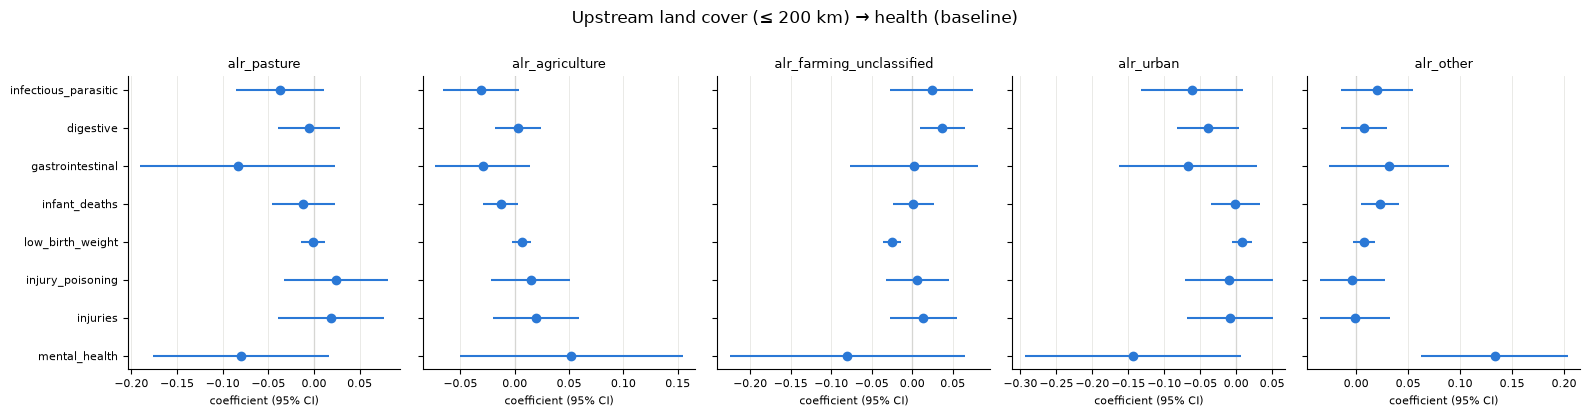

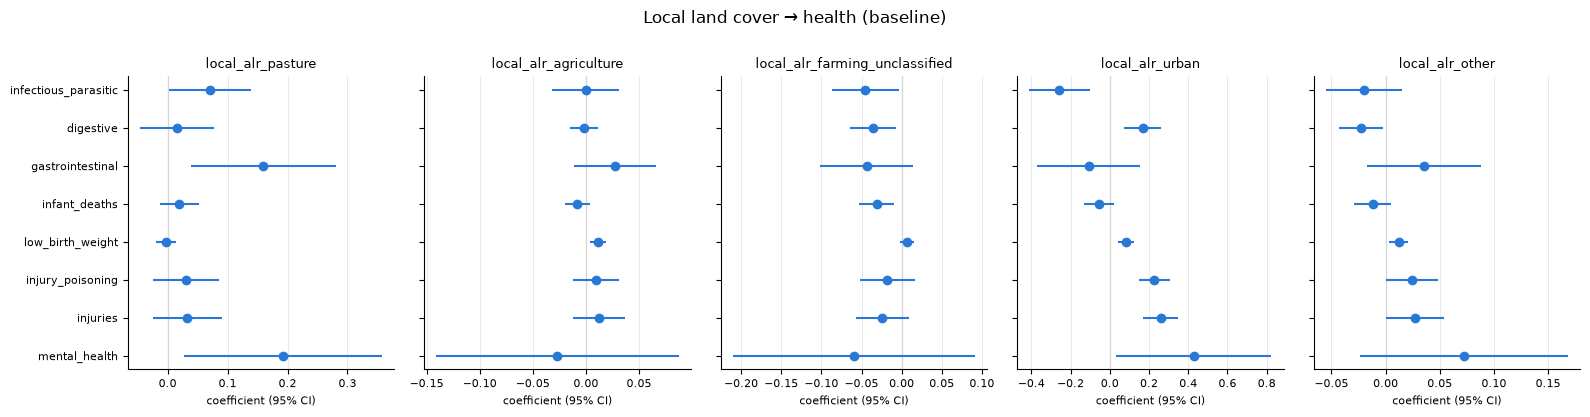

In [7]:
coefficient_plot(main, UPSTREAM, title="Upstream land cover (≤ 200 km) → health (baseline)")
coefficient_plot(main, LOCAL, title="Local land cover → health (baseline)")

**Reading the results (run of 2026-10-22).**
- **Upstream pasture and agriculture.** No coefficient is significant at 5% for any
  primary or placebo outcome. Most estimates for water-related outcomes are negative
  (pasture / agriculture: infectious −0.037 / −0.031, gastrointestinal −0.084 / −0.030,
  infant deaths −0.012 / −0.013), and the injury placebo's are positive (+0.024 / +0.015).
- **Precision.** Within-municipality SDs are 0.20 (pasture) and 0.45 (agriculture), so
  the 95% CIs exclude increases above about 0.6% and 1.1% per SD in every primary
  outcome (e.g. infant deaths: at most +0.5% per SD of pasture).
- **Other upstream classes.** Unclassified farming → digestive +0.037 and low birth
  weight −0.025; "other" non-natural land → infant deaths +0.023 and the mental-health
  placebo +0.13 (all p < 0.05).
- **Local block.** Local urbanization has the largest coefficients, and they are largest
  for the placebos (injury/poisoning +0.23, injuries +0.26). They are also large for
  digestive (+0.17), low birth weight (+0.08) and infectious (−0.26). This looks like
  local development and access to hospital care, not water. Local pasture →
  gastrointestinal (+0.16, SE 0.06) is the one water-plausible local association.

### 3.1 Difference from the placebo

Each primary outcome is stacked with the injury/poisoning placebo (ICD 19) in one PPML
fit with outcome-specific FE (municipality and state×year, each × outcome), and every
regressor also enters interacted with the primary-outcome indicator. PPML separates by
outcome, so the interaction coefficients equal the difference between the two separate
fits' coefficients exactly; Otto-3 clustering accounts for their correlation (same
municipalities and years). A water effect should differ from the placebo, not only from
zero.

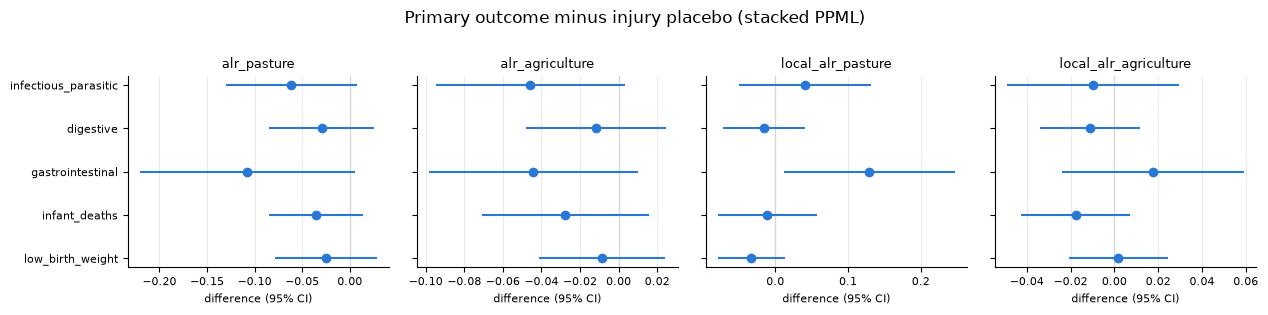

In [8]:
PLACEBO_REFERENCE = "injury_poisoning"
STACK_TERMS = UPSTREAM + LOCAL + CONTROLS
DIFF = {term: f"{term}_diff" for term in UPSTREAM + LOCAL}


def stacked(name, reference=PLACEBO_REFERENCE, data=None):
    # Long frame of `name` (is_outcome = 1) and the placebo (0), with interacted regressors and FE.
    data = df if data is None else data
    parts = []
    for outcome, is_outcome in [(name, 1), (reference, 0)]:
        part = data[["mun_id", "state_year", "otto_basin_l3", *STACK_TERMS]].copy()
        part["y"] = data[H.outcome_column(outcome)]
        part["log_exposure"] = data[H.offset_column(outcome)]
        part["is_outcome"] = is_outcome
        parts.append(part)
    long = pd.concat(parts, ignore_index=True).dropna(subset=["y", "log_exposure"])
    for term in STACK_TERMS:
        long[f"{term}_diff"] = long[term] * long["is_outcome"]
    flag = long["is_outcome"].astype(str)
    long["mun_stack"] = long["mun_id"] + "_" + flag
    long["state_year_stack"] = long["state_year"] + "_" + flag
    return long


RHS_STACKED = " + ".join(STACK_TERMS + [f"{term}_diff" for term in STACK_TERMS])
diff_fits = {name: pf.fepois(f"y ~ {RHS_STACKED} | mun_stack + state_year_stack", data=stacked(name),
                             offset="log_exposure", vcov=VCOV)
             for name in PRIMARY}
difference = tidy(diff_fits, "minus placebo")
difference = difference[difference["Coefficient"].isin(DIFF.values())].copy()
difference["Coefficient"] = difference["Coefficient"].str.removesuffix("_diff")
coefficient_plot(difference, ["alr_pasture", "alr_agriculture", "local_alr_pasture", "local_alr_agriculture"],
                 title="Primary outcome minus injury placebo (stacked PPML)", xlabel="difference (95% CI)")

**Reading the results (run of 2026-10-22).** No upstream coefficient differs from the injury placebo at 5%. The differences are mostly
negative, so water outcomes respond *less* to upstream pasture and agriculture than
injuries do. Examples: infectious minus placebo, pasture −0.061 (SE 0.035) and
agriculture −0.046 (0.025); gastrointestinal, pasture −0.108 (0.058). Local pasture →
gastrointestinal exceeds the placebo by +0.13 (SE 0.06; bootstrap p = 0.057, §8.2). The
significant local differences involve urban and "other" land, with every primary outcome
below the placebo: the placebo's stronger response to local urbanization.

## 4. Secondary outcomes

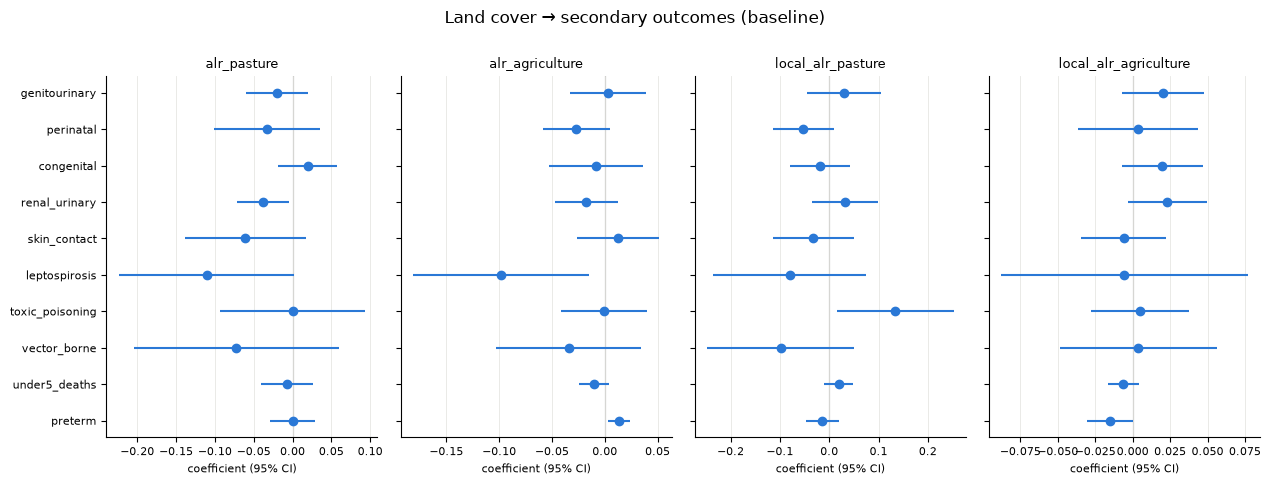

In [9]:
secondary_fits = fit_all(SECONDARY)
secondary = tidy(secondary_fits, "baseline")
coefficient_plot(secondary, ["alr_pasture", "alr_agriculture", "local_alr_pasture", "local_alr_agriculture"],
                 title="Land cover → secondary outcomes (baseline)")

**Reading the results (run of 2026-10-22).** 23 of 100 land-cover coefficients are significant at 5% (5 expected), but most involve
local urban land or unclassified farming, and the signs are mixed. Upstream pasture
lowers renal/urinary hospitalizations (−0.038, SE 0.017). Upstream agriculture lowers
leptospirosis (−0.10, 0.04; only 2,441 cases a year) and raises preterm births (+0.013,
0.005; 2012–2024). No secondary outcome shows an adverse upstream pasture effect.

## 5. Robustness

Primary and placebo outcomes under the alternatives in the decision table: OLS on
population-weighted log rates of positive counts, dropping 2020–21, upstream exposure
only, the utilization control (hospitalization outcomes), the upstream climate block,
municipality + biome×year FE, the current SIH system only (2008–2024), and municipalities
with upstream rings only.

spec                                        baseline  OLS log rate  drop 2020–21  upstream only  + utilization  + upstream climate  mun + biome×year FE  2008–2024  has upstream only
outcome              Coefficient                                                                                                                                                     
infectious_parasitic alr_pasture              -0.037        -0.044        -0.038         -0.002         -0.026              -0.037               -0.113     -0.049             -0.032
                     alr_agriculture          -0.031        -0.021        -0.031         -0.037         -0.014              -0.032               -0.044     -0.044             -0.033
                     local_alr_pasture         0.071         0.089         0.069            NaN          0.045               0.071                 0.12      0.065              0.064
                     local_alr_agriculture        -0        -0.016         0.006            NaN         -0.001                  -0                0.023      0.006                 -0
digestive            alr_pasture              -0.006         0.001        -0.005          0.004          0.002              -0.006               -0.035      0.001              -0.01
                     alr_agriculture           0.003            -0         0.004          0.006          0.011               0.003               -0.014      0.006             -0.003
                     local_alr_pasture         0.015         0.023         0.013            NaN         -0.003               0.014                0.005     -0.004              0.013
                     local_alr_agriculture    -0.002        -0.002        -0.001            NaN         -0.002              -0.001                0.013     -0.008                 -0
gastrointestinal     alr_pasture              -0.084        -0.085         -0.08          0.003         -0.094              -0.084               -0.041     -0.128             -0.083
                     alr_agriculture           -0.03        -0.013        -0.024         -0.014         -0.002               -0.03               -0.039     -0.075             -0.036
                     local_alr_pasture          0.16         0.264         0.153            NaN           0.16                0.16                0.301      0.202               0.14
                     local_alr_agriculture     0.027        -0.006         0.024            NaN          0.021               0.027                 0.05      0.032              0.029
infant_deaths        alr_pasture              -0.012        -0.018        -0.014         -0.002            NaN              -0.012               -0.036     -0.018             -0.014
                     alr_agriculture          -0.013        -0.015        -0.014         -0.019            NaN              -0.012               -0.019     -0.018             -0.013
                     local_alr_pasture          0.02         0.024         0.018            NaN            NaN                0.02                0.048      0.023              0.021
                     local_alr_agriculture    -0.008        -0.003        -0.008            NaN            NaN              -0.008                0.001      0.007             -0.009
low_birth_weight     alr_pasture              -0.001            -0            -0         -0.002            NaN              -0.001               -0.004         -0             -0.005
                     alr_agriculture           0.006         0.005         0.006          0.014            NaN               0.006                0.007      0.002              0.004
                     local_alr_pasture        -0.002         0.004        -0.001            NaN            NaN              -0.002               -0.003     -0.011             -0.002
                     local_alr_agriculture     0.011         0.011         0.011            NaN            NaN               0.011                0.005       0.01              0.

,coefficients,same_sign_as_baseline,significant_5pct
spec,,,
baseline,80,1,21
OLS log rate,80,0.9,21
drop 2020–21,80,0.975,19
upstream only,40,0.75,8
+ utilization,60,0.8333,15
+ upstream climate,80,0.9875,21
mun + biome×year FE,80,0.8375,22
2008–2024,80,0.825,17
has upstream only,80,0.9375,21


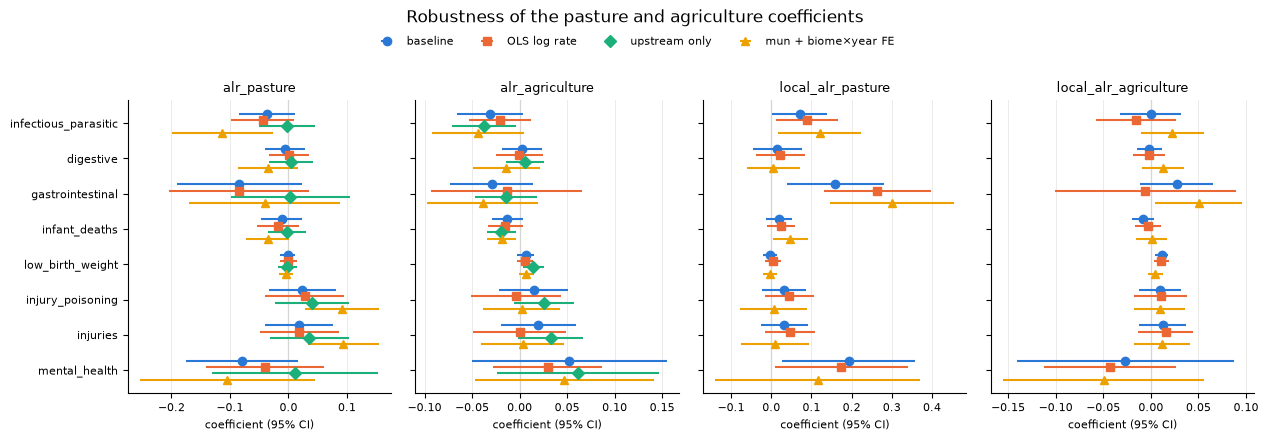

In [10]:
ROBUST_OUTCOMES = PRIMARY + PLACEBO
HOSPITALIZATION = [name for name in ROBUST_OUTCOMES if name in H.HOSPITALIZATION_OUTCOMES]
UPSTREAM_CLIMATE = list(H.UPSTREAM_CLIMATE_CONTROLS.values())
ROBUSTNESS_SPECS = {
    "OLS log rate": dict(method="ols"),
    "drop 2020–21": dict(data=df[~df["year"].isin(H.COVID_YEARS)]),
    "upstream only": dict(rhs=" + ".join(UPSTREAM + CONTROLS)),
    "+ utilization": dict(rhs=f"{RHS} + {H.UTILIZATION_CONTROL}"),
    "+ upstream climate": dict(rhs=" + ".join([RHS, *UPSTREAM_CLIMATE])),
    "mun + biome×year FE": dict(fe="mun_id + biome_year"),
    "2008–2024": dict(data=df[df["year"] >= H.SIH_FIRST_CURRENT_YEAR]),
    "has upstream only": dict(data=df[df["has_upstream"]]),
}
robustness = [main]
for spec, kwargs in ROBUSTNESS_SPECS.items():
    names = HOSPITALIZATION if spec == "+ utilization" else ROBUST_OUTCOMES
    robustness.append(tidy(fit_all(names, **kwargs), spec))
robustness = pd.concat(robustness, ignore_index=True)

KEY_TERMS = ["alr_pasture", "alr_agriculture", "local_alr_pasture", "local_alr_agriculture"]
key = robustness[robustness["Coefficient"].isin(KEY_TERMS)]
display(key.pivot_table(index=["outcome", "Coefficient"], columns="spec", values="Estimate", sort=False)
        [["baseline", *ROBUSTNESS_SPECS]].round(3))
baseline_sign = np.sign(main.set_index(["outcome", "Coefficient"])["Estimate"])
upstream_land_cover = robustness[robustness["Coefficient"].isin(UPSTREAM + LOCAL)]
display(upstream_land_cover.assign(
    same_sign=lambda t: np.sign(t["Estimate"]).to_numpy()
    == baseline_sign.reindex(pd.MultiIndex.from_frame(t[["outcome", "Coefficient"]])).to_numpy(),
    significant=lambda t: t["Pr(>|t|)"] < 0.05,
).groupby("spec", sort=False).agg(coefficients=("Estimate", "size"), same_sign_as_baseline=("same_sign", "mean"),
                                  significant_5pct=("significant", "sum")).loc[["baseline", *ROBUSTNESS_SPECS]])
coefficient_plot(robustness, KEY_TERMS, specs=["baseline", "OLS log rate", "upstream only", "mun + biome×year FE"],
                 title="Robustness of the pasture and agriculture coefficients")

**Reading the results (run of 2026-10-22).**
- **Sign agreement.** Signs agree with the baseline for 82–99% of the land-cover
  coefficients in every specification except upstream-only (75%). Without the local block
  the upstream terms absorb local change.
- **Biome×year FE.** This specification moves the estimates most: upstream pasture →
  infectious −0.11, and the injury placebo becomes positive and significant (+0.09,
  p = 0.004). State×year FE absorb state-level trends that biome×year leaves in, which
  supports the baseline choice.
- **Where pasture or agriculture becomes significant.** That happens 11 times in a primary
  outcome, mostly negative. The two positive cases are small: agriculture → LBW +0.014
  (upstream only) and → digestive +0.011 (with the utilization control), at most 0.65%
  per within-SD.
- **Small changes.** Dropping 2020–21, adding upstream climate, the 2008–2024 window and
  municipalities with upstream rings only all change little.

## 6. Distance bands

Separate upstream ALR terms for 0–50, 50–150 and 150–500 km (local block and controls as
in the baseline). Municipalities without rings in a band get 0 for it, absorbed by the
municipality FE (their reach is fixed over time), so each band is identified from the
municipalities that have it.

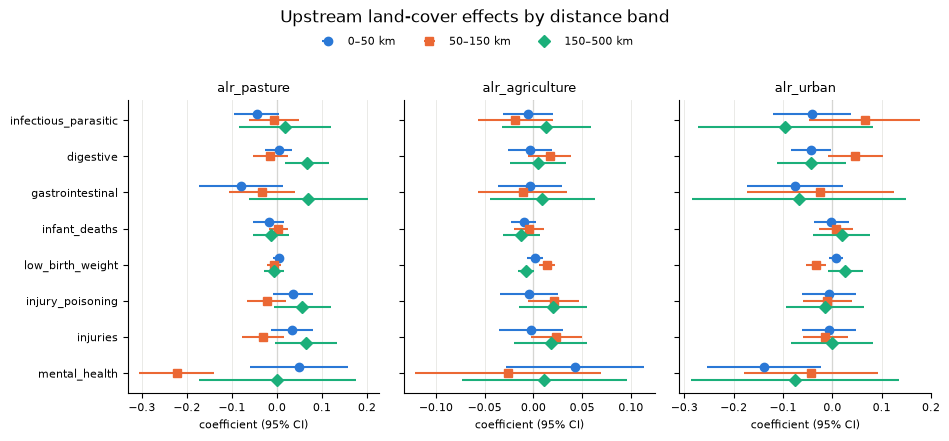

In [11]:
BANDED = [f"{regressor}__{band}" for band in H.DISTANCE_BANDS for regressor in UPSTREAM]
band_fits = fit_all(PRIMARY + PLACEBO, rhs=" + ".join(BANDED + LOCAL + CONTROLS))
bands = tidy(band_fits, "bands")

band_long = bands[bands["Coefficient"].isin(BANDED)].copy()
band_long[["regressor", "band"]] = band_long["Coefficient"].str.split("__", expand=True)
band_long["spec"] = band_long["band"].map({b: f"{lo}–{hi} km" for b, (lo, hi) in H.DISTANCE_BANDS.items()})
band_long["Coefficient"] = band_long["regressor"]
coefficient_plot(band_long, ["alr_pasture", "alr_agriculture", "alr_urban"],
                 specs=[f"{lo}–{hi} km" for lo, hi in H.DISTANCE_BANDS.values()],
                 title="Upstream land-cover effects by distance band")

**Reading the results (run of 2026-10-22).** 14 of 120 band coefficients are significant at 5% (6 expected), with no distance
gradient: far-band (150–500 km) "other" land raises the injury placebos (+0.05) as much
as infant deaths (+0.04). As in the pollution arm, the data cannot separate distances,
and the capped exposure stays the baseline.

## 7. Heterogeneity by biome

Biome-specific slopes for upstream pasture and agriculture (Pampa and Pantanal pooled);
the other regressors keep a common slope.

biome_group,Mata Atlântica,Cerrado,Caatinga,Amazônia,Pampa/Pantanal
municipalities,2693,1102,1096,502,169


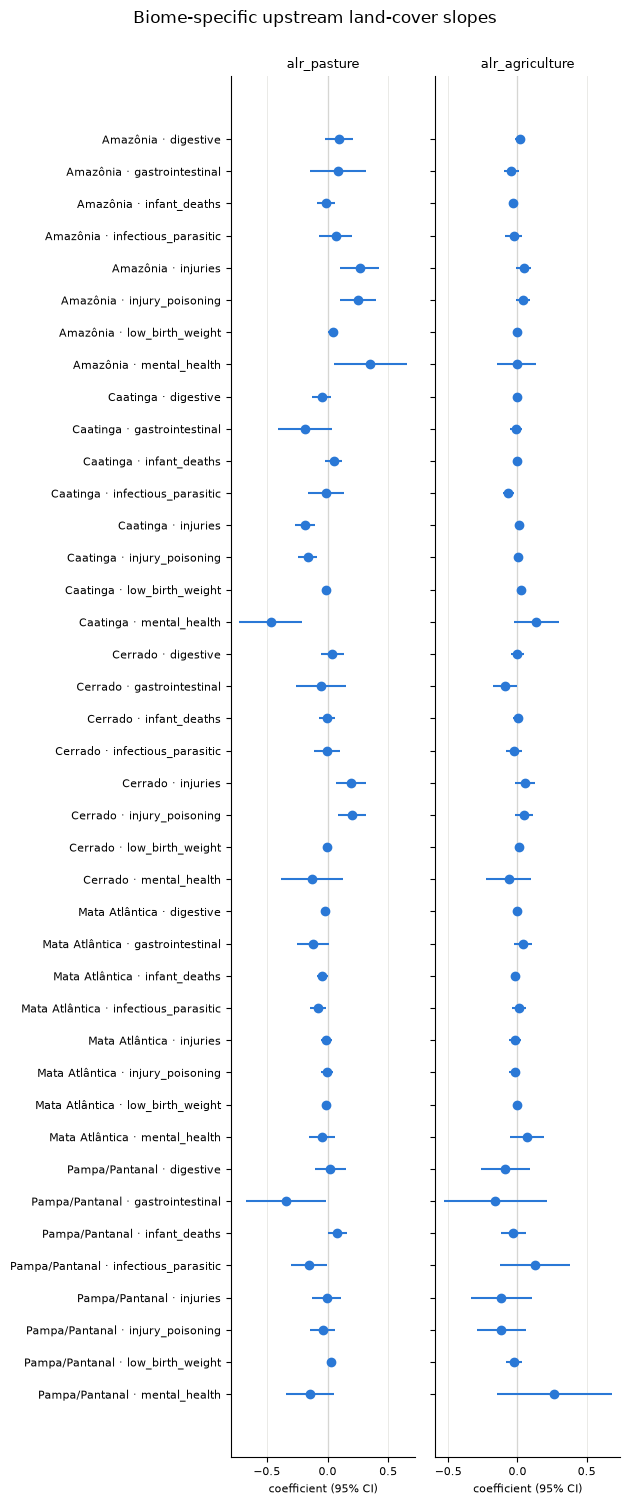

In [12]:
display(municipalities["biome_group"].value_counts().rename("municipalities").to_frame().T)
other_upstream = [r for r in UPSTREAM if r not in ("alr_pasture", "alr_agriculture")]
RHS_BIOME = " + ".join(["i(biome_group, alr_pasture)", "i(biome_group, alr_agriculture)"] + other_upstream + LOCAL + CONTROLS)
biome_fits = fit_all(PRIMARY + PLACEBO, rhs=RHS_BIOME)
biome = tidy(biome_fits, "by biome")

biome_long = biome[biome["Coefficient"].str.startswith("biome_group::")].copy()
parts = biome_long["Coefficient"].str.extract(r"biome_group::(?P<biome>.+):(?P<regressor>alr_\w+)$")
biome_long["Coefficient"] = parts["regressor"]
biome_long["outcome"] = parts["biome"] + " · " + biome_long["outcome"]
coefficient_plot(biome_long.sort_values("outcome"), ["alr_pasture", "alr_agriculture"], specs=["by biome"],
                 title="Biome-specific upstream land-cover slopes")

**Reading the results (run of 2026-10-22).** 17 of 80 biome slopes are significant at 5% (4 expected). The clearest pattern is in the
**placebo**: injury hospitalizations rise with upstream pasture in the Amazon (+0.25) and
the Cerrado (+0.20), the agricultural frontier, and fall in the Caatinga (−0.16).
Mental-health hospitalizations follow the same pattern. Water outcomes show no consistent
biome pattern (e.g. Mata Atlântica pasture → infectious −0.08, Amazon pasture → LBW
+0.05). Frontier pasture expansion goes with more injuries (occupational, violence),
which upstream water quality cannot explain.

## 8. Inference

### 8.1 Clustering level
Standard errors of the baseline fits under alternative clusterings, recomputed on the
same fits; ratios are relative to the Otto-3 baseline.

In [13]:
CLUSTERINGS = {"state": {"CRV1": "state"}, "Otto 3 (baseline)": VCOV, "Otto 4": {"CRV1": "otto_basin_l4"}}
rows = []
for outcome, model in main_fits.items():
    for label, vcov in CLUSTERINGS.items():
        model.vcov(vcov)
        table = model.tidy().loc[UPSTREAM + LOCAL]
        rows.append(table.assign(outcome=outcome, clustering=label, n_clusters=model._G[0]).reset_index())
    model.vcov(VCOV)  # restore the baseline inference
inference = pd.concat(rows, ignore_index=True)

standard_errors = inference.pivot_table(index=["outcome", "Coefficient"], columns="clustering", values="Std. Error")
se_ratio = standard_errors.div(standard_errors["Otto 3 (baseline)"], axis=0)
display(se_ratio[list(CLUSTERINGS)].describe(percentiles=[0.1, 0.5, 0.9]).T.round(2))
display(inference.groupby("clustering").agg(
    clusters=("n_clusters", "median"),
    significant_5pct=("Pr(>|t|)", lambda p: int((p < 0.05).sum())),
    tests=("Pr(>|t|)", "size"),
).loc[list(CLUSTERINGS)])

,count,mean,std,min,10%,50%,90%,max
clustering,,,,,,,,
state,80,1.06,0.2,0.6,0.76,1.07,1.32,1.45
Otto 3 (baseline),80,1,0,1,1,1,1,1
Otto 4,80,0.95,0.1,0.7,0.82,0.96,1.08,1.3


,clusters,significant_5pct,tests
clustering,,,
state,26,18,80
Otto 3 (baseline),217,21,80
Otto 4,821,23,80


**Reading the results (run of 2026-10-22).** State clustering (26 clusters) gives SEs 7% larger at the median, and Otto 4 4% smaller;
18, 21 and 23 of 80 coefficients are significant at 5% under state, Otto 3 and Otto 4. The
Otto-3 baseline sits between the two.

### 8.2 Wild-cluster score bootstrap

PPML has no demeaned OLS form to resample, so the restricted wild-cluster **score**
bootstrap (Kline and Santos 2012; `inference.poisson_score_bootstrap`, 9,999 Rademacher
draws over Otto-3 basins) tests each land-cover coefficient of the baseline fits and each
placebo difference of §3.1.

In [14]:
BOOT_REPS = 9_999
boot_rows = []
for family, fits, terms in [("baseline", main_fits, UPSTREAM + LOCAL), ("minus placebo", diff_fits, list(DIFF.values()))]:
    for outcome, model in fits.items():
        analytic = model.tidy()
        for term in terms:
            row = poisson_score_bootstrap(model, term, cluster="otto_basin_l3", reps=BOOT_REPS, seed=20261022)
            row["outcome"], row["family"] = outcome, family
            row["Estimate"] = analytic.loc[term, "Estimate"]
            row["p_analytic"] = analytic.loc[term, "Pr(>|t|)"]
            boot_rows.append(row)
bootstrap = pd.DataFrame(boot_rows)
bootstrap["Coefficient"] = bootstrap["Coefficient"].str.removesuffix("_diff")

display(bootstrap.groupby("family").agg(
    tests=("p_wcb", "size"),
    clusters=("n_clusters", "median"),
    analytic_5pct=("p_analytic", lambda p: int((p < 0.05).sum())),
    bootstrap_5pct=("p_wcb", lambda p: int((p < 0.05).sum())),
    bootstrap_1pct=("p_wcb", lambda p: int((p < 0.01).sum())),
))
display(bootstrap[(bootstrap["p_wcb"] < 0.05) | (bootstrap["p_analytic"] < 0.05)]
        .sort_values(["family", "p_wcb"])
        [["family", "outcome", "Coefficient", "Estimate", "p_analytic", "p_wcb", "n_clusters"]])

,tests,clusters,analytic_5pct,bootstrap_5pct,bootstrap_1pct
family,,,,,
baseline,80,217,21,16,8
minus placebo,50,217,8,6,4


,family,outcome,Coefficient,Estimate,p_analytic,p_wcb,n_clusters
18,baseline,digestive,local_alr_urban,0.1674,0.0005239,0,217
48,baseline,low_birth_weight,local_alr_urban,0.08266,3.617e-05,0,217
58,baseline,injury_poisoning,local_alr_urban,0.2269,2.992e-08,0,217
68,baseline,injuries,local_alr_urban,0.2597,1.184e-08,0,217
42,baseline,low_birth_weight,alr_farming_unclassified,-0.02474,1.093e-05,0.0002,217
74,baseline,mental_health,alr_other,0.1331,0.0002064,0.001,217
37,baseline,infant_deaths,local_alr_farming_unclassified,-0.03123,0.005735,0.009601,217
8,baseline,infectious_parasitic,local_alr_urban,-0.2568,0.001083,0.009701,217
49,baseline,low_birth_weight,local_alr_other,0.01208,0.00601,0.0127,217
46,baseline,low_birth_weight,local_alr_agriculture,0.01123,0.00238,0.0133,217


**Reading the results (run of 2026-10-22).**
- **Baseline.** 16 of 80 tests pass the score bootstrap at 5% (21 analytically).
  12 of them are local-block terms, 6 of those local urban (4 with p < 0.0001).
- **Upstream terms.** 4 of 40 pass (2 expected); they are the ones listed in §3.
- **Minus placebo.** 6 of 50 tests pass, all for local urban or "other" land. No upstream
  difference passes; the smallest p-values are 0.052 for agriculture and 0.053 for
  pasture → infectious, both negative.
- **p = 0.** No draw exceeded the observed statistic (p < 1e-4).

## 9. Mining arm

Mining is a local, point-like source, so, as in the pollution arm, its exposure is
measured within **50 km** upstream and the model is estimated only on municipalities with
any mining in that reach over 2000–2024. Four mining regressors are added to the baseline
specification:

- `upstream_mining_present_50`: mining appears in the 50 km upstream reach (identified from
  municipalities where it switches on or off);
- `upstream_mining_pp_50`: percentage points of that reach under mining (intensity);
- `local_mining_present`, `local_mining_pp`: the same for the municipality's own rings, so
  the upstream terms are net of the local mining economy (income, migration, occupational
  injuries).

Outcomes are those where a metal signature is expected: nervous-system (ICD 06, mercury)
and blood (ICD 03, lead-induced anaemia) hospitalizations, renal/urinary (cadmium, lead),
toxic poisoning, congenital and perinatal hospitalizations, low birth weight, preterm
births and infant deaths. The injury placebos should respond to local, not upstream,
mining.

In [15]:
mining = df[df[H.MINING_MUNICIPALITY]].copy()
MINING_TERMS = H.UPSTREAM_MINING_REGRESSORS + H.LOCAL_MINING_REGRESSORS
presence = mining.groupby("mun_id")[[H.UPSTREAM_MINING_PRESENT, H.LOCAL_MINING_PRESENT]].agg(["min", "max"])
switchers = {column: presence.index[(presence[(column, "min")] == 0) & (presence[(column, "max")] == 1)]
             for column in [H.UPSTREAM_MINING_PRESENT, H.LOCAL_MINING_PRESENT]}
print(f"Mining municipalities: {mining.mun_id.nunique():,} ({mining.otto_basin_l3.nunique()} Otto-3 basins); "
      f"switching upstream presence: {len(switchers[H.UPSTREAM_MINING_PRESENT]):,} "
      f"({mining[mining.mun_id.isin(switchers[H.UPSTREAM_MINING_PRESENT])].otto_basin_l3.nunique()} basins); "
      f"switching local presence: {len(switchers[H.LOCAL_MINING_PRESENT]):,}; municipality-years: {len(mining):,}")
display(mining.drop_duplicates("mun_id")["biome"].value_counts().rename("mining municipalities").to_frame().T)
display(pd.DataFrame({
    "upstream (50 km)": mining.loc[mining[H.UPSTREAM_MINING_PRESENT] == 1, H.UPSTREAM_MINING_PP].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]),
    "local": mining.loc[mining[H.LOCAL_MINING_PRESENT] == 1, H.LOCAL_MINING_PP].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]),
}).T.rename_axis("mined share (pp), where present", axis=1))
display(desc.demean(mining, MINING_TERMS, ["mun_id", "state_year"]).corr().round(2))

Mining municipalities: 1,190 (115 Otto-3 basins); switching upstream presence: 216 (43 basins); switching local presence: 111; municipality-years: 29,706


biome,Mata Atlântica,Cerrado,Amazônia,Caatinga,Pampa,Pantanal
mining municipalities,586,258,169,156,16,5


"mined share (pp), where present",count,mean,std,min,25%,50%,75%,90%,99%,max
upstream (50 km),2.659e+04,0.2316,0.8416,1.986e-05,0.005681,0.02945,0.1443,0.4837,3.002,21.94
local,1.609e+04,0.2738,0.7458,2.846e-06,0.009114,0.04713,0.1872,0.6779,3.386,14.7


,upstream_mining_present_50,upstream_mining_pp_50,local_mining_present,local_mining_pp
upstream_mining_present_50,1,-0.04,0.09,-0.03
upstream_mining_pp_50,-0.04,1,-0.01,0.31
local_mining_present,0.09,-0.01,1,-0.01
local_mining_pp,-0.03,0.31,-0.01,1


**Reading the results (run of 2026-10-22).** The mining sample has 1,190 municipalities in 115 Otto-3 basins. 216 switch upstream presence (in 43 basins) and 111 switch local presence. Mined shares are tiny: a median
0.03 pp of the 50 km reach (0.05 pp locally) where present. Upstream and local mining
move nearly independently within municipality (correlation 0.09 for presence, 0.31 for
intensity), so the two can be separated.

### 9.1 Estimates

In [16]:
MINING_ARM = H.MINING_OUTCOMES + H.MINING_PLACEBO_OUTCOMES
RHS_MINING = " + ".join(MINING_TERMS) + " + " + RHS
mining_fits = fit_all(MINING_ARM, data=mining, rhs=RHS_MINING)
mining_table = tidy(mining_fits, "mining arm")
pf.etable(list(mining_fits.values()), keep=MINING_TERMS)

GT(_tbl_data=  __index_level_0__           __index_level_1__                    0                    1                    2                      3                    4                    5                    6                    7  \
0              coef  upstream_mining_present_50  -0.043 <br> (0.066)  -0.047 <br> (0.054)  -0.062 <br> (0.047)     0.087 <br> (0.065)   0.057 <br> (0.069)   0.095 <br> (0.073)  -0.005 <br> (0.015)  -0.010 <br> (0.020)   
1              coef       upstream_mining_pp_50   0.016 <br> (0.071)   0.007 <br> (0.041)  0.082* <br> (0.037)    -0.037 <br> (0.070)  -0.034 <br> (0.025)  -0.035 <br> (0.042)  -0.006 <br> (0.009)   0.008 <br> (0.011)   
2              coef        local_mining_present   0.148 <br> (0.102)  0.173* <br> (0.068)   0.092 <br> (0.058)     0.014 <br> (0.095)   0.008 <br> (0.056)  -0.033 <br> (0.060)   0.005 <br> (0.011)  -0.018 <br> (0.034)   
3              coef             local_mining_pp  0.107* <br> (0.042)  -0.053 <br> (0.048)  -0.021 <br> (0.026)  -0.253** <br> (0.090)   0.027 <br> (0.039)  -0.029 <br> (0.037)  -0.009 <br> (0.016)  -0.002 <br> (0.017)   
4                fe                  state_year                    x                    x                    x                      x                    x                    x                    x                    x   
5                fe                     mun_id                     x                    x                    x                      x                    x                    x                    x                    x   
6             stats                Observations               29,681               29,681               29,681                 29,681               29,681               29,681               29,677               15,455   
7             stats                          R²                    -                    -                    -                      -                    -                    -                    -                    -   

                    8                    9                   10  
0  0.046 <br> (0.028)   0.006 <br> (0.028)   0.004 <br> (0.031)  
1  0.004 <br> (0.015)  -0.030 <br> (0.018)  -0.033 <br> (0.020)  
2  0.006 <br> (0.032)   0.038 <br> (0.054)   0.044 <br> (0.050)  
3  0.021 <br> (0.014)   0.014 <br> (0.046)   0.012 <br> (0.048)  
4                   x                    x                    x  
5                   x                    x                    x  
6              29,675               29,681               29,681  
7                   -                    -                    -  , _body=<great_tables._gt_data.Body object at 0x14bd752f1190>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label='(1)', column_align='center', column_width=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label='(2)', column_align='center', column_width=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label='(3)', column_align='center', column_width=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label='(4)', column_align='center', column_width=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label='(5)', column_align='center', column_width=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label='(6)', column_align='center', column_width=None), ColInfo(var='6', type=<ColInfoTypeEnum.default: 1>, column_label='(7)', column_align='center', column_width=None), ColInfo(var='7', type=<ColInfoTypeEnum.default: 1>, column_label='(8)', column_align='center', column_width=None), ColInfo(var='8', type=<ColInfoTypeEnum.default: 1>, column_label='(9)', column_align='center', column_width=None),

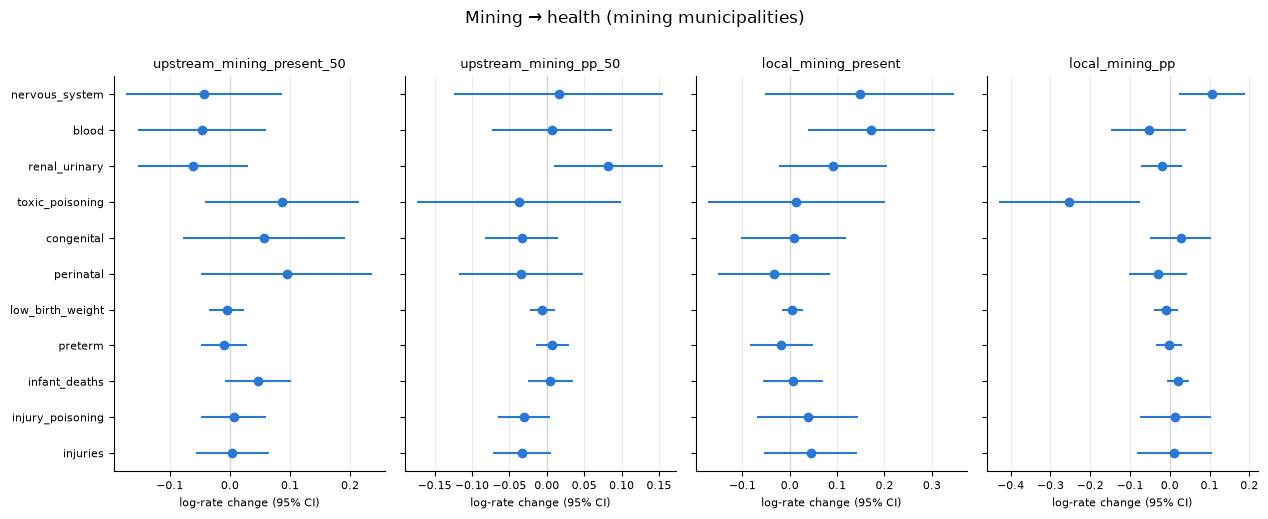

In [17]:
coefficient_plot(mining_table, MINING_TERMS, title="Mining → health (mining municipalities)", xlabel="log-rate change (95% CI)")

**Reading the results (run of 2026-10-22).**
- **Upstream mining.** No pooled upstream coefficient is significant at 5%. The largest presence estimates are for perinatal
  (+0.095, SE 0.073), toxic poisoning (+0.087) and infant deaths (+0.046, SE 0.028,
  p = 0.10). Upstream intensity raises renal/urinary hospitalizations (+0.082 per pp,
  p = 0.03).
- **Local mining.** It has the other significant terms: presence → blood disorders +0.17
  (p = 0.01); intensity → nervous system +0.11 per pp (p = 0.01) and toxic poisoning
  −0.25 (p = 0.005).
- **Placebo.** The injury placebos respond to neither upstream nor local mining.

### 9.2 Wild-cluster score bootstrap for the mining coefficients

In [18]:
mining_boot_rows = []
for outcome, model in mining_fits.items():
    analytic = model.tidy()
    for term in MINING_TERMS:
        row = poisson_score_bootstrap(model, term, cluster="otto_basin_l3", reps=BOOT_REPS, seed=20261022)
        row["outcome"], row["family"] = outcome, "mining"
        row["Estimate"] = analytic.loc[term, "Estimate"]
        row["p_analytic"] = analytic.loc[term, "Pr(>|t|)"]
        mining_boot_rows.append(row)
mining_boot = pd.DataFrame(mining_boot_rows)
display(mining_boot.groupby("Coefficient", sort=False).agg(
    tests=("p_wcb", "size"), clusters=("n_clusters", "median"),
    analytic_5pct=("p_analytic", lambda p: int((p < 0.05).sum())),
    bootstrap_5pct=("p_wcb", lambda p: int((p < 0.05).sum())),
))
display(mining_boot[["outcome", "Coefficient", "Estimate", "p_analytic", "p_wcb", "n_clusters"]]
        .sort_values(["Coefficient", "p_wcb"]).set_index(["Coefficient", "outcome"]))

,tests,clusters,analytic_5pct,bootstrap_5pct
Coefficient,,,,
upstream_mining_present_50,11,115,0,0
upstream_mining_pp_50,11,115,1,0
local_mining_present,11,115,1,0
local_mining_pp,11,115,2,2


Estimate  p_analytic   p_wcb  n_clusters
Coefficient                outcome                                                   
local_mining_pp            toxic_poisoning    -0.2528    0.005115  0.0241         115
                           nervous_system      0.1071     0.01138  0.0318         115
                           infant_deaths       0.0211      0.1353  0.2596         115
                           congenital         0.02715       0.486   0.336         115
                           renal_urinary     -0.02057      0.4277  0.4754         115
                           perinatal         -0.02942      0.4285  0.6235         115
                           blood             -0.05299      0.2735  0.7568         115
                           injury_poisoning    0.0138      0.7624  0.7694         115
                           injuries           0.01173      0.8087  0.8341         115
                           low_birth_weight -0.008923      0.5685  0.8709         115
                           preterm          -0.002034      0.9035  0.8834         115
local_mining_present       blood               0.1725     0.01139 0.07451         115
                           renal_urinary      0.09221      0.1126  0.1491         115
                           injuries           0.04385      0.3852  0.3672         115
                           nervous_system      0.1481      0.1456  0.3998         115
                           injury_poisoning   0.03827       0.481  0.4553         115
                           perinatal         -0.03285      0.5845  0.5886         115
                           preterm             -0.018      0.5945  0.5968         115
                           low_birth_weight  0.005488      0.6194  0.6352         115
                           infant_deaths     0.006421      0.8419  0.8469         115
                           toxic_poisoning      0.014      0.8831  0.8811         115
                           congenital        0.008464      0.8809  0.8929         115
upstream_mining_pp_50      renal_urinary      0.08232     0.02603 0.09851         115
                           injuries          -0.03279         0.1  0.1595         115
                           injury_poisoning  -0.03029     0.08565  0.1716         115
                           congenital        -0.03374      0.1768  0.2277         115
                           perinatal         -0.03463      0.4108  0.3474         115
                           low_birth_weight -0.006301      0.4602   0.395         115
                           preterm           0.007582      0.4964  0.5647         115
                           toxic_poisoning    -0.0369      0.5967  0.6489         115
                           infant_deaths     0.004454      0.7722  0.7975         115
                           nervous_system     0.01627      0.8194  0.8363         115
                           blood             0.006784      0.8685  0.8746         115
upstream_mining_present_50 infant_deaths      0.04642     0.09807 0.08151         115
                           toxic_poisoning     0.0869      0.1824  0.2177         115
                           renal_urinary     -0.06154      0.1885  0.2211         115
                           perinatal           0.0945      0.1947  0.2936         115
                           blood             -0.04711      0.3853  0.4361         115
                           congenital         0.05653      0.4113  0.4414         115
                           nervous_system    -0.04269      0.5205  0.5633         115
                           preterm          -0.009777       0.619  0.6229         115
                           low_birth_weight  -0.00512      0.7307  0.7393         115
                           injury_poisoning  0.006037      0.8282    0.83         115
                           injuries          0.003573      0.9082  0.9107         115

**Reading the results (run of 2026-10-22).** 2 of 44 mining coefficients pass the score bootstrap at 5%, about what chance produces
(2.2). Both are local intensity: toxic poisoning (−0.25, p = 0.024) and nervous system (+0.11,
p = 0.032). Upstream intensity → renal (p = 0.10), local presence → blood (p = 0.07) and
upstream presence → infant deaths (p = 0.08) lose significance. Pooled over all biomes,
there is no robust mining effect.

### 9.3 Amazon

Mercury-using gold mining (*garimpo*) is concentrated in the Amazon, while mining
elsewhere is mostly industrial (iron ore, aggregates, bauxite). Upstream and local
presence get separate Amazon and non-Amazon slopes (explicit interaction columns, so the
score bootstrap applies); intensity keeps a common slope. The Amazon slopes are identified
from far fewer municipalities and basins than the pooled ones.

Amazon: 169 mining municipalities, 36 switching upstream presence in 18 Otto-3 basins


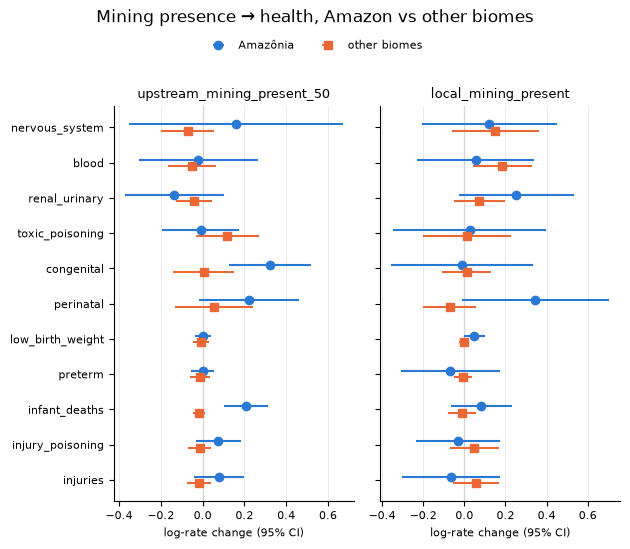

Estimate                                                           Std. Error                                                           p_analytic  \
Coefficient      upstream_mining_present_50__amazon upstream_mining_present_50__other upstream_mining_present_50__amazon upstream_mining_present_50__other upstream_mining_present_50__amazon   
outcome                                                                                                                                                                                         
nervous_system                                 0.16                            -0.071                               0.26                             0.064                               0.54   
blood                                        -0.021                            -0.052                              0.145                             0.058                              0.886   
renal_urinary                                -0.135                            -0.043                              0.122                             0.043                              0.268   
toxic_poisoning                               -0.01                             0.118                              0.095                             0.077                              0.913   
congenital                                    0.321                             0.004                                0.1                             0.076                              0.001   
perinatal                                     0.224                             0.055                              0.122                             0.096                              0.067   
low_birth_weight                              0.004                            -0.008                               0.02                             0.019                              0.849   
preterm                                      -0.001                            -0.012                              0.029                             0.024                              0.982   
infant_deaths                                 0.207                            -0.019                              0.053                             0.015                                  0   
injury_poisoning                              0.074                            -0.014                              0.055                             0.028                              0.174   
injuries                                      0.078                            -0.018                               0.06                              0.03                              0.193   

                                                                                p_wcb                                    
Coefficient      upstream_mining_present_50__other upstream_mining_present_50__amazon upstream_mining_present_50__other  
outcome                                                                                                                  
nervous_system                               0.266                              0.534                             0.346  
blood                                         0.37                              0.906                             0.436  
renal_urinary                                0.326                               0.56                             0.349  
toxic_poisoning                              0.124                              0.917                             0.179  
congenital                                   0.957                              0.087                              0.96  
perinatal                                    0.564                              0.046                             0.802  
low_birth_weight                             0.662                              0.867                             0.662  
preterm                                      0.618                              0.983                             0.625 

In [19]:
amazon = (mining["biome"] == "Amazônia").astype(float)
REGION_TERMS = {}
for term in [H.UPSTREAM_MINING_PRESENT, H.LOCAL_MINING_PRESENT]:
    for region, indicator in [("amazon", amazon), ("other", 1 - amazon)]:
        mining[f"{term}__{region}"] = mining[term] * indicator
        REGION_TERMS[f"{term}__{region}"] = (term, "Amazônia" if region == "amazon" else "other biomes")
amazon_switchers = switchers[H.UPSTREAM_MINING_PRESENT].intersection(mining.loc[amazon == 1, "mun_id"].unique())
print(f"Amazon: {mining.loc[amazon == 1, 'mun_id'].nunique()} mining municipalities, {len(amazon_switchers)} switching upstream "
      f"presence in {mining[mining.mun_id.isin(amazon_switchers)].otto_basin_l3.nunique()} Otto-3 basins")

RHS_AMAZON = " + ".join([*REGION_TERMS, H.UPSTREAM_MINING_PP, H.LOCAL_MINING_PP, RHS])
amazon_fits = fit_all(MINING_ARM, data=mining, rhs=RHS_AMAZON)
amazon_table = tidy(amazon_fits, "mining arm by region")
amazon_long = amazon_table[amazon_table["Coefficient"].isin(REGION_TERMS)].copy()
amazon_long["spec"] = amazon_long["Coefficient"].map(lambda term: REGION_TERMS[term][1])
amazon_long["Coefficient"] = amazon_long["Coefficient"].map(lambda term: REGION_TERMS[term][0])
coefficient_plot(amazon_long, [H.UPSTREAM_MINING_PRESENT, H.LOCAL_MINING_PRESENT], specs=["Amazônia", "other biomes"],
                 title="Mining presence → health, Amazon vs other biomes", xlabel="log-rate change (95% CI)")

amazon_boot_rows = []
for outcome, model in amazon_fits.items():
    analytic = model.tidy()
    for term in [f"{H.UPSTREAM_MINING_PRESENT}__amazon", f"{H.UPSTREAM_MINING_PRESENT}__other"]:
        row = poisson_score_bootstrap(model, term, cluster="otto_basin_l3", reps=BOOT_REPS, seed=20261022)
        row["outcome"], row["family"] = outcome, "mining by region"
        row["Estimate"], row["Std. Error"] = analytic.loc[term, "Estimate"], analytic.loc[term, "Std. Error"]
        row["p_analytic"] = analytic.loc[term, "Pr(>|t|)"]
        amazon_boot_rows.append(row)
amazon_boot = pd.DataFrame(amazon_boot_rows)
display(amazon_boot.pivot_table(index="outcome", columns="Coefficient", values=["Estimate", "Std. Error", "p_analytic", "p_wcb"],
                                sort=False).round(3))

**Reading the results (run of 2026-10-22).**
- **Amazon.** The Amazon has 169 mining municipalities and 36 onsets in 18 basins. There,
  mining appearing upstream raises:
  - infant deaths by +0.21 (SE 0.05, i.e. +23%, bootstrap p = 0.002);
  - perinatal hospitalizations by +0.22 (p = 0.046);
  - congenital anomalies by +0.32 (analytic p = 0.001, bootstrap 0.087).
- **Elsewhere.** The same slopes are near zero (infant deaths −0.02, congenital 0.00,
  perinatal +0.06).
- **Placebo.** The Amazon injury placebos are smaller and not significant (+0.07, +0.08;
  p ≥ 0.44).
- **Multiple testing.** Of the 22 regional presence tests, infant deaths is the only one
  that survives a Bonferroni correction (0.05 / 22 = 0.0023), and only narrowly.

### 9.4 Event study: mining onset upstream in the Amazon

Every Amazon municipality that switches upstream presence does so from no mining to
mining. Event-time indicators around the first year with mining within 50 km upstream
(bins −5 or earlier … +5 or later, year −1 omitted) replace the Amazon presence slope in
§9.3's specification. Never-switching mining municipalities and the non-Amazon slope stay
as in §9.3. Flat pre-onset coefficients support reading the post-onset ones as effects of
mining. With 36 onsets in 18 basins they are imprecise, and the usual staggered-adoption
caveats apply.

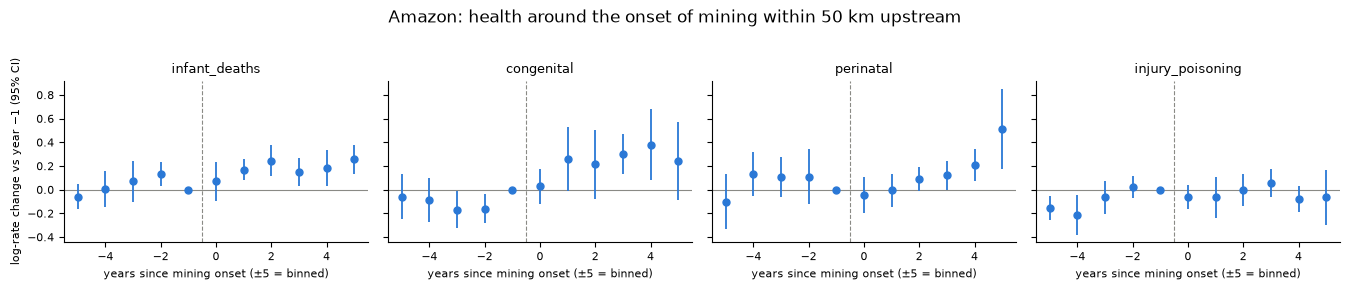

,mean pre-onset (−5…−2),pre-onset significant at 5%,mean post-onset (0…+5),post-onset significant at 5%
outcome,,,,
infant_deaths,0.037,1,0.178,5
congenital,-0.12,2,0.236,2
perinatal,0.062,0,0.147,2
injury_poisoning,-0.102,2,-0.036,0


In [20]:
EVENT_BINS = range(-5, 6)
onset_year = (mining[mining.mun_id.isin(amazon_switchers) & (mining[H.UPSTREAM_MINING_PRESENT] == 1)]
              .groupby("mun_id")["year"].min())
event_time = (mining["year"] - mining["mun_id"].map(onset_year)).clip(-5, 5)
EVENT_TERMS = {}
for k in EVENT_BINS:
    if k == -1:
        continue
    name = f"event_{'m' if k < 0 else 'p'}{abs(k)}"
    mining[name] = (event_time == k).astype(float)
    EVENT_TERMS[name] = k
RHS_EVENT = " + ".join([*EVENT_TERMS, f"{H.UPSTREAM_MINING_PRESENT}__other", f"{H.LOCAL_MINING_PRESENT}__amazon",
                        f"{H.LOCAL_MINING_PRESENT}__other", H.UPSTREAM_MINING_PP, H.LOCAL_MINING_PP, RHS])
EVENT_OUTCOMES = ["infant_deaths", "congenital", "perinatal", "injury_poisoning"]
event_fits = fit_all(EVENT_OUTCOMES, data=mining, rhs=RHS_EVENT)
event_table = tidy(event_fits, "event study")
event_long = event_table[event_table["Coefficient"].isin(EVENT_TERMS)].assign(k=lambda t: t["Coefficient"].map(EVENT_TERMS))

fig, axes = plt.subplots(1, len(EVENT_OUTCOMES), figsize=(3.4 * len(EVENT_OUTCOMES), 2.8), sharey=True)
for ax, outcome in zip(axes, EVENT_OUTCOMES):
    sub = pd.concat([event_long[event_long["outcome"] == outcome],
                     pd.DataFrame({"k": [-1], "Estimate": [0.0], "2.5%": [0.0], "97.5%": [0.0]})]).sort_values("k")
    ax.errorbar(sub["k"], sub["Estimate"], yerr=[sub["Estimate"] - sub["2.5%"], sub["97.5%"] - sub["Estimate"]],
                fmt="o", ms=5, lw=1.3, capsize=0, color=SERIES_COLORS[0])
    ax.axhline(0, color="#8a8a85", lw=0.8, zorder=0)
    ax.axvline(-0.5, color="#8a8a85", lw=0.8, ls="--", zorder=0)
    ax.set_title(outcome, fontsize=9)
    ax.set_xlabel("years since mining onset (±5 = binned)", fontsize=8)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("log-rate change vs year −1 (95% CI)", fontsize=8)
fig.suptitle("Amazon: health around the onset of mining within 50 km upstream", y=1.02)
plt.tight_layout()
plt.show()

pre = event_long[event_long["k"] < -1]
post = event_long[event_long["k"] >= 0]
display(pd.DataFrame({
    "mean pre-onset (−5…−2)": pre.groupby("outcome")["Estimate"].mean(),
    "pre-onset significant at 5%": pre.groupby("outcome")["Pr(>|t|)"].apply(lambda p: int((p < 0.05).sum())),
    "mean post-onset (0…+5)": post.groupby("outcome")["Estimate"].mean(),
    "post-onset significant at 5%": post.groupby("outcome")["Pr(>|t|)"].apply(lambda p: int((p < 0.05).sum())),
}).loc[EVENT_OUTCOMES].round(3))

**Reading the results (run of 2026-10-22).**
- **Infant deaths.** Near zero 5 to 3 years before onset, then a step up from year +1
  (+0.15 to +0.26) that persists; 5 of 6 post-onset coefficients are significant. There
  is one pre-onset bump (+0.13 at year −2, significant), so a small anticipation effect or
  trend cannot be ruled out.
- **Congenital anomalies.** The post-onset rise (+0.2 to +0.4) partly mirrors a pre-onset
  dip (−0.17 and −0.16 at years −3 and −2), so §9.3's slope overstates it.
- **Perinatal.** Flat until year +2, rising at +3 to +5; no jump at onset.
- **Injury placebo.** No post-onset change (mean −0.04); its only significant
  coefficients are negative, at years −5 and −4.

Infant deaths is the most credible mining result: prenatal and early-life mercury exposure
is a known pathway, the rise follows onset, and the placebo does not move. It rests on 36
onsets in 18 basins.

### 9.5 Mining in the full-sample model

Adds the 200 km upstream `alr_mining` (and its local counterpart) to the baseline on all
municipalities. This shows what the main model would attribute to mining, and whether
leaving mining out moves the other land-cover coefficients.

In [21]:
capped_mining = panels.adm2_upstream_land_cover(max_km=H.MAX_UPSTREAM_KM, years=H.ANALYSIS_YEARS)[["mun_id", "year", "alr_mining"]]
full = df.merge(capped_mining, on=["mun_id", "year"], how="left", validate="one_to_one")
full["alr_mining"] = full["alr_mining"].fillna(0.0)  # headwater: constant, absorbed by the municipality FE
with_mining_fits = fit_all(MINING_ARM, data=full, rhs=f"{RHS} + alr_mining + local_alr_mining")
with_mining = tidy(with_mining_fits, "baseline + alr_mining")
display(with_mining[with_mining["Coefficient"].isin(["alr_mining", "local_alr_mining"])]
        .pivot_table(index="outcome", columns="Coefficient", values=["Estimate", "Pr(>|t|)"], sort=False).round(3))

baseline_mining_outcomes = tidy(fit_all(MINING_ARM, data=full), "baseline")
shift = (baseline_mining_outcomes[baseline_mining_outcomes["Coefficient"].isin(UPSTREAM + LOCAL)]
         .merge(with_mining[with_mining["Coefficient"].isin(UPSTREAM + LOCAL)],
                on=["outcome", "Coefficient"], suffixes=("_baseline", "_with_mining")))
shift["shift_in_se"] = (shift["Estimate_with_mining"] - shift["Estimate_baseline"]) / shift["Std. Error_baseline"]
display(shift["shift_in_se"].abs().describe(percentiles=[0.5, 0.9]).rename("|coefficient shift| in baseline SEs").to_frame().T)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Estimate                    Pr(>|t|)                 
Coefficient      alr_mining local_alr_mining alr_mining local_alr_mining
outcome                                                                 
nervous_system       -0.022            0.031      0.408            0.406
blood                 0.023            0.013      0.114            0.672
renal_urinary        -0.012            0.055      0.357             0.03
toxic_poisoning      -0.008           -0.035      0.858            0.572
congenital            0.003             0.01      0.829            0.728
perinatal            -0.063           -0.015      0.065            0.584
low_birth_weight     -0.016           -0.023      0.018            0.001
preterm               -0.01            0.008      0.032             0.32
infant_deaths         0.013                0      0.203            0.978
injury_poisoning     -0.034            0.021      0.064            0.416
injuries             -0.036            0.008       0.05            0.765

,count,mean,std,min,50%,90%,max
|coefficient shift| in baseline SEs,110,0.09289,0.08553,0.002938,0.06975,0.172,0.437


**Reading the results (run of 2026-10-22).**
- **Full sample.** Over all municipalities, 200 km upstream `alr_mining` is significant
  only for low birth weight (−0.016) and preterm (−0.010), both negative. Local
  `alr_mining` raises renal/urinary hospitalizations (+0.055, p = 0.03) and lowers LBW
  (−0.023).
- **Omission check.** Adding mining moves the other land-cover coefficients by a median
  0.07 and at most 0.44 of their SEs, so leaving it out of the baseline does not bias
  them.

## 10. Results export

In [22]:
results = pd.concat([main.assign(family="baseline"), difference.assign(family="minus placebo"),
                     secondary.assign(family="secondary"), robustness[robustness["spec"] != "baseline"].assign(family="robustness"),
                     bands.assign(family="bands"), biome.assign(family="biome"),
                     inference.rename(columns={"clustering": "spec"}).assign(family="inference"),
                     mining_table.assign(family="mining"), amazon_table.assign(family="mining"), event_table.assign(family="mining"),
                     with_mining.assign(family="mining")], ignore_index=True)
results.to_csv(RESULTS_DIR / "coefficients.csv", index=False)
pd.concat([bootstrap, mining_boot, amazon_boot], ignore_index=True).to_csv(RESULTS_DIR / "wild_cluster_bootstrap.csv", index=False)
print(f"{len(results):,} coefficient rows -> {RESULTS_DIR.relative_to(PROJECT_ROOT) / 'coefficients.csv'}")

2,345 coefficient rows -> output/analysis/health/coefficients.csv
